# CP1 · Data yang dipelajari baseline
**EDA terarah untuk presentasi 10 menit · Chronic Wound · train aktual**

**Alur:** fakta data → hubungan dengan metode penulis → demo preprocessing → batas interpretasi.
Notebook ini sudah dieksekusi: tabel dan empat visual dapat dibaca langsung. Tidak menjalankan model,
training, inference, atau pembentukan split. Semua hitungan memakai train dari manifest baseline tersimpan.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/build_cp1_eda.py').is_file())
sys.path.insert(0, str(ROOT/'scripts'))
from build_cp1_eda import load_verified, stats_table, bin_table, configure_style
from cp1_eda import sha, CSV, SUMMARY
import pandas as pd
from IPython.display import display, HTML, Markdown, Image
s, frame, pipeline, verification = load_verified(check_raw=True)
display(HTML("""<style>
.dataframe {border-collapse:collapse;font-size:14px} .dataframe th {background:#352B43;color:white;padding:9px}
.dataframe td {padding:8px;border-bottom:1px solid #DDD5E8} .dataframe tr:nth-child(even){background:#FAF7F2}
</style>"""))
def table(df): display(HTML(df.to_html(index=False,border=0,na_rep='—',float_format=lambda x:f'{x:.4f}')))
def figure(name): display(Image(filename=str(ROOT/'reports/figures/cp1-eda-01'/name),width=1100))
print(f"✓ {len(frame)} train aktual; pasangan, hash raw, hitungan piksel, statistik, dan demo terverifikasi.")
print('Manifest:',s['manifest']['manifest_path'])
print('SHA-256:',s['manifest']['manifest_sha256'])
print('Membership dibaca dari manifest run, tanpa shuffle atau split baru.')

✓ 707 train aktual; pasangan, hash raw, hitungan piksel, statistik, dan demo terverifikasi.
Manifest: outputs/runs/cp1-baseline-01/split-manifest.json
SHA-256: 596e3b0d61e372eb9001bbd8c567f6345e986e498f74b3514b96f6f9f954e5a2
Membership dibaca dari manifest run, tanpa shuffle atau split baru.


## FAKTA DATASET DARI EDA KAMI
### 1 · Target biner dan inventaris train
Mask mentah diperiksa **sebelum** binarisasi; foreground = grayscale 255, background = 0.
Kanal RGB mask tersimpan identik. Ini target segmentasi biner, bukan kategori klinis.

In [2]:
table(pd.DataFrame([
    ('Foto train',s['n_images']),('Mask train',s['n_masks']),('Filename unik',s['n_unique_filenames']),
    ('Resolusi foto dan mask',str(s['resolutions'])),('Nilai unik mask mentah',str(s['mask_unique_values_raw'])),
    ('GT kosong',f"{s['n_empty_gt']} ({s['empty_gt_percent']:.2f}%)"),('GT positif',s['n_positive_gt'])
],columns=['Audit','Hasil']))

Audit,Hasil
Foto train,707
Mask train,707
Filename unik,707
Resolusi foto dan mask,"[{'height': 224, 'width': 224, 'n_images': 707, 'n_masks': 707}]"
Nilai unik mask mentah,"[0, 255]"
GT kosong,43 (6.08%)
GT positif,664


### 2 · Ketidakseimbangan piksel
**Denominator:** seluruh piksel single-channel mask train, termasuk padding hitam bawaan.
`foreground_pct_global = Σ foreground / Σ(H×W) × 100`. Ini **bukan** proporsi jaringan tubuh atau luas fisik.

Piksel,Jumlah,Persen kanvas
Luka,958034,2.7006
Background,34516398,97.2994
Seluruh mask,35474432,100.0000


**Background:luka = 36.0284:1.** Jika total foreground nol, rasio disimpan sebagai null (tidak terdefinisi).

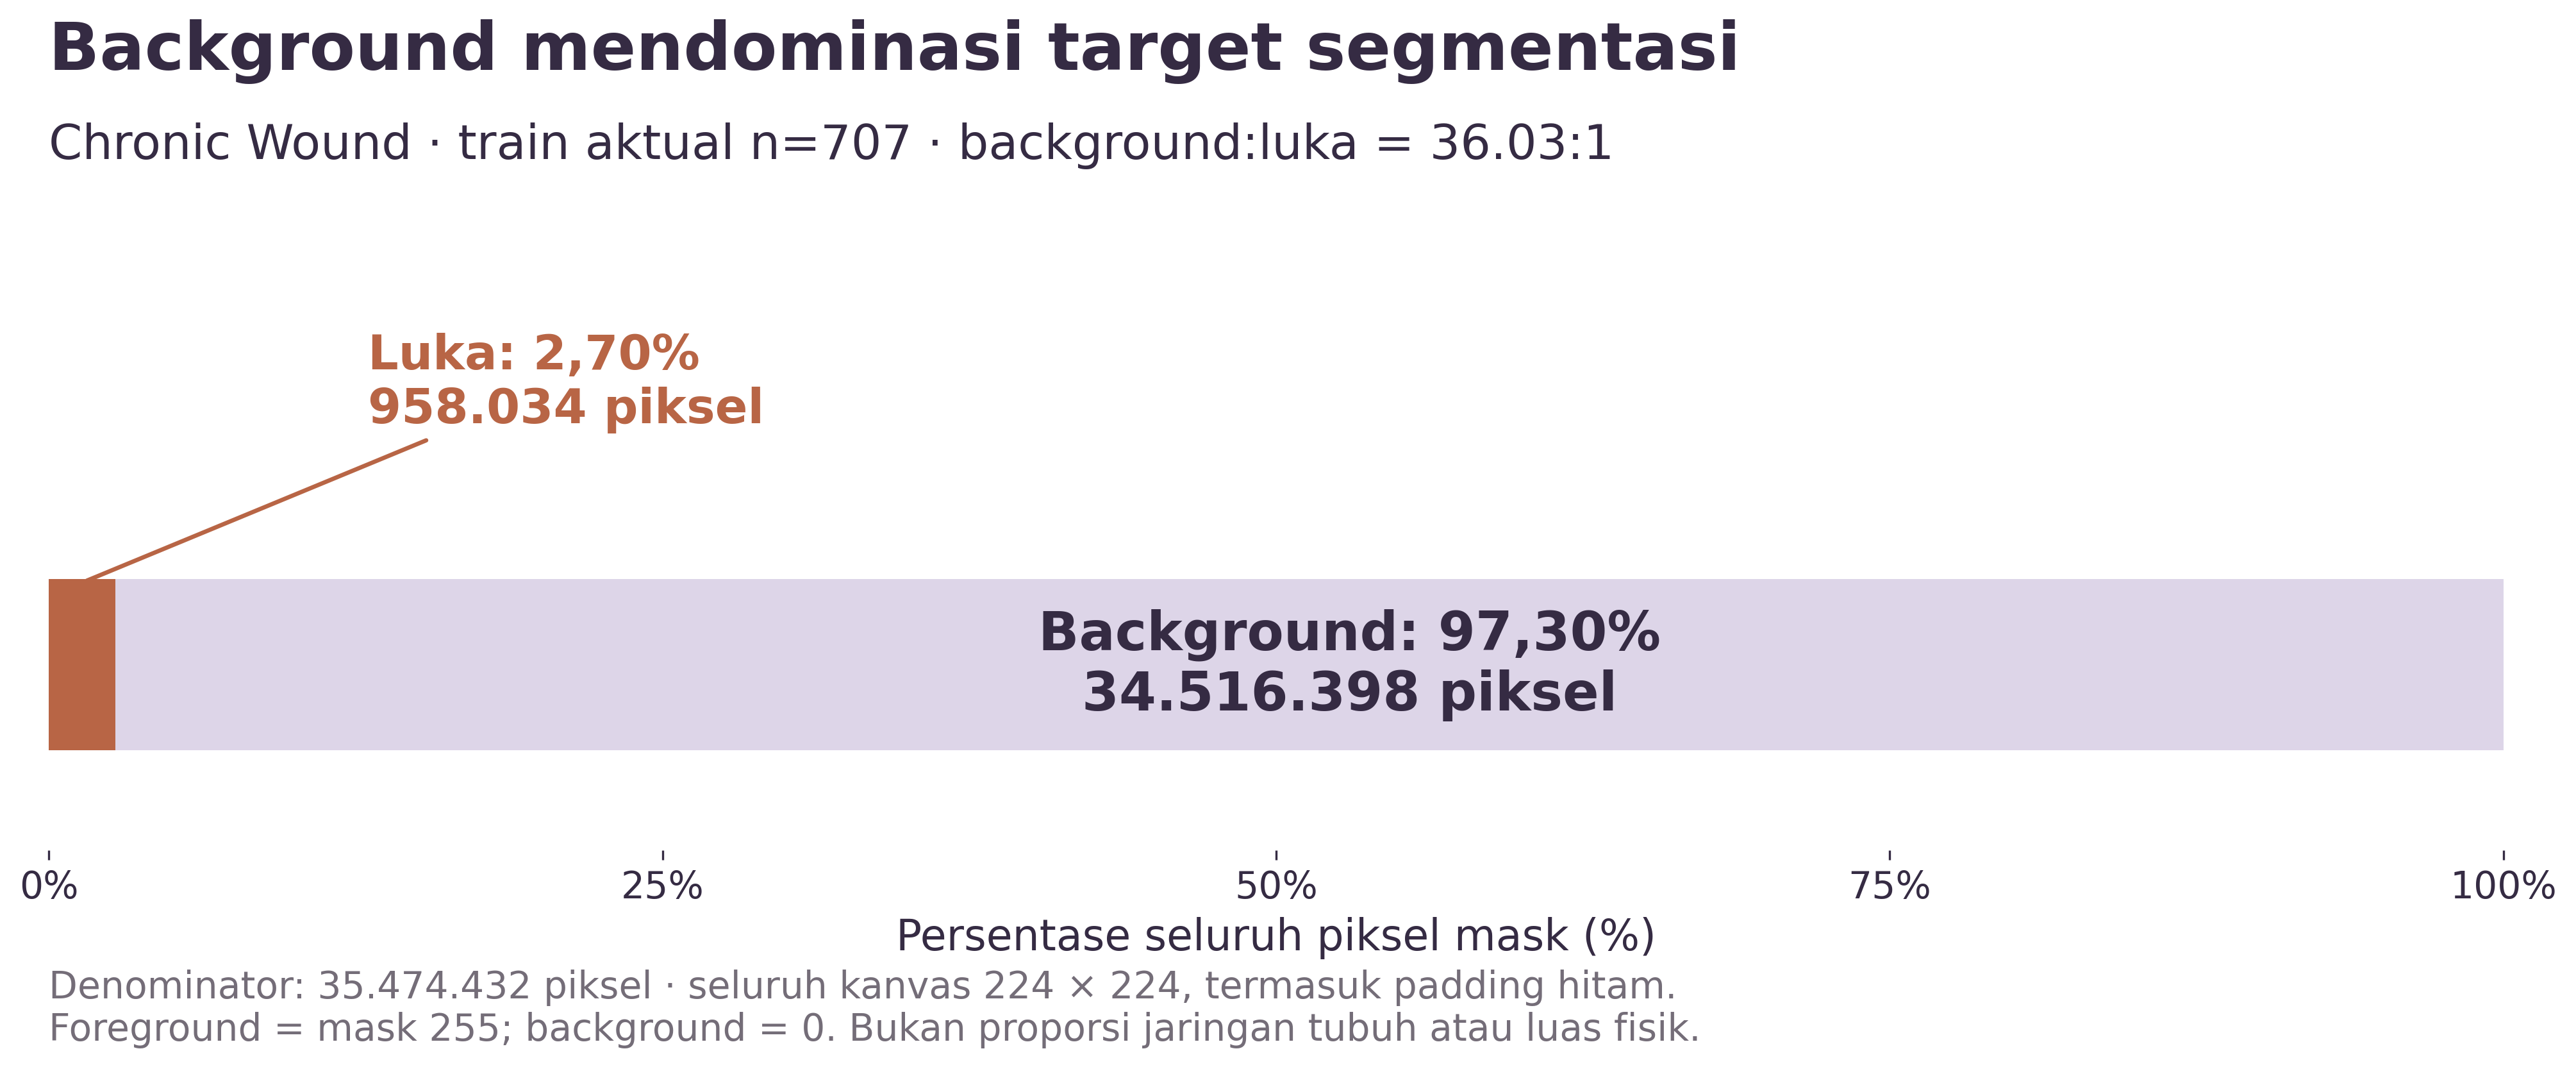

In [3]:
table(pd.DataFrame([
    ('Luka',s['total_foreground_pixels'],s['foreground_pct_global']),
    ('Background',s['total_background_pixels'],s['background_pct_global']),
    ('Seluruh mask',s['total_mask_pixels'],100.)
],columns=['Piksel','Jumlah','Persen kanvas']))
display(Markdown(f"**Background:luka = {s['background_foreground_ratio']:.4f}:1.** "
                 "Jika total foreground nol, rasio disimpan sebagai null (tidak terdefinisi)."))
figure('01_pixel_composition.png')

### 3 · Luas dan posisi: cakupan statistik dibedakan
`area_fraction_i = foreground_pixels_i / (H_i × W_i)`. Tabel dalam **persen**; kuantil interpolasi linear.
Semua gambar dan GT positif memiliki denominator gambar berbeda. Karena resolusi seluruh train seragam,
persentase global sama dengan rata-rata persentase per gambar **untuk cakupan seluruh train yang sama**.
Bin bersifat deskriptif, bukan klinis atau kategori C1–C9. Centroid adalah rata-rata pusat semua piksel
foreground relatif terhadap kanvas; tidak terdefinisi pada GT kosong, bukan posisi anatomis.

Cakupan,n,Min (%),Q1 (%),Median (%),Q3 (%),Max (%),Mean (%)
Seluruh train,707,0.0000,0.7733,1.7538,3.5814,27.3477,2.7006
GT positif saja,664,0.0060,0.8799,1.8943,3.7149,27.3477,2.8755


Bin luas kanvas,Jumlah gambar,% dari seluruh train
Kosong,43,6.0820
">0–0,5%",76,10.7496
">0,5–1%",119,16.8317
>1–5%,359,50.7779
>5–10%,94,13.2956
>10%,16,2.2631


Mean seluruh train = 2.700632%; global = 2.700632%
Jumlah bin = 707


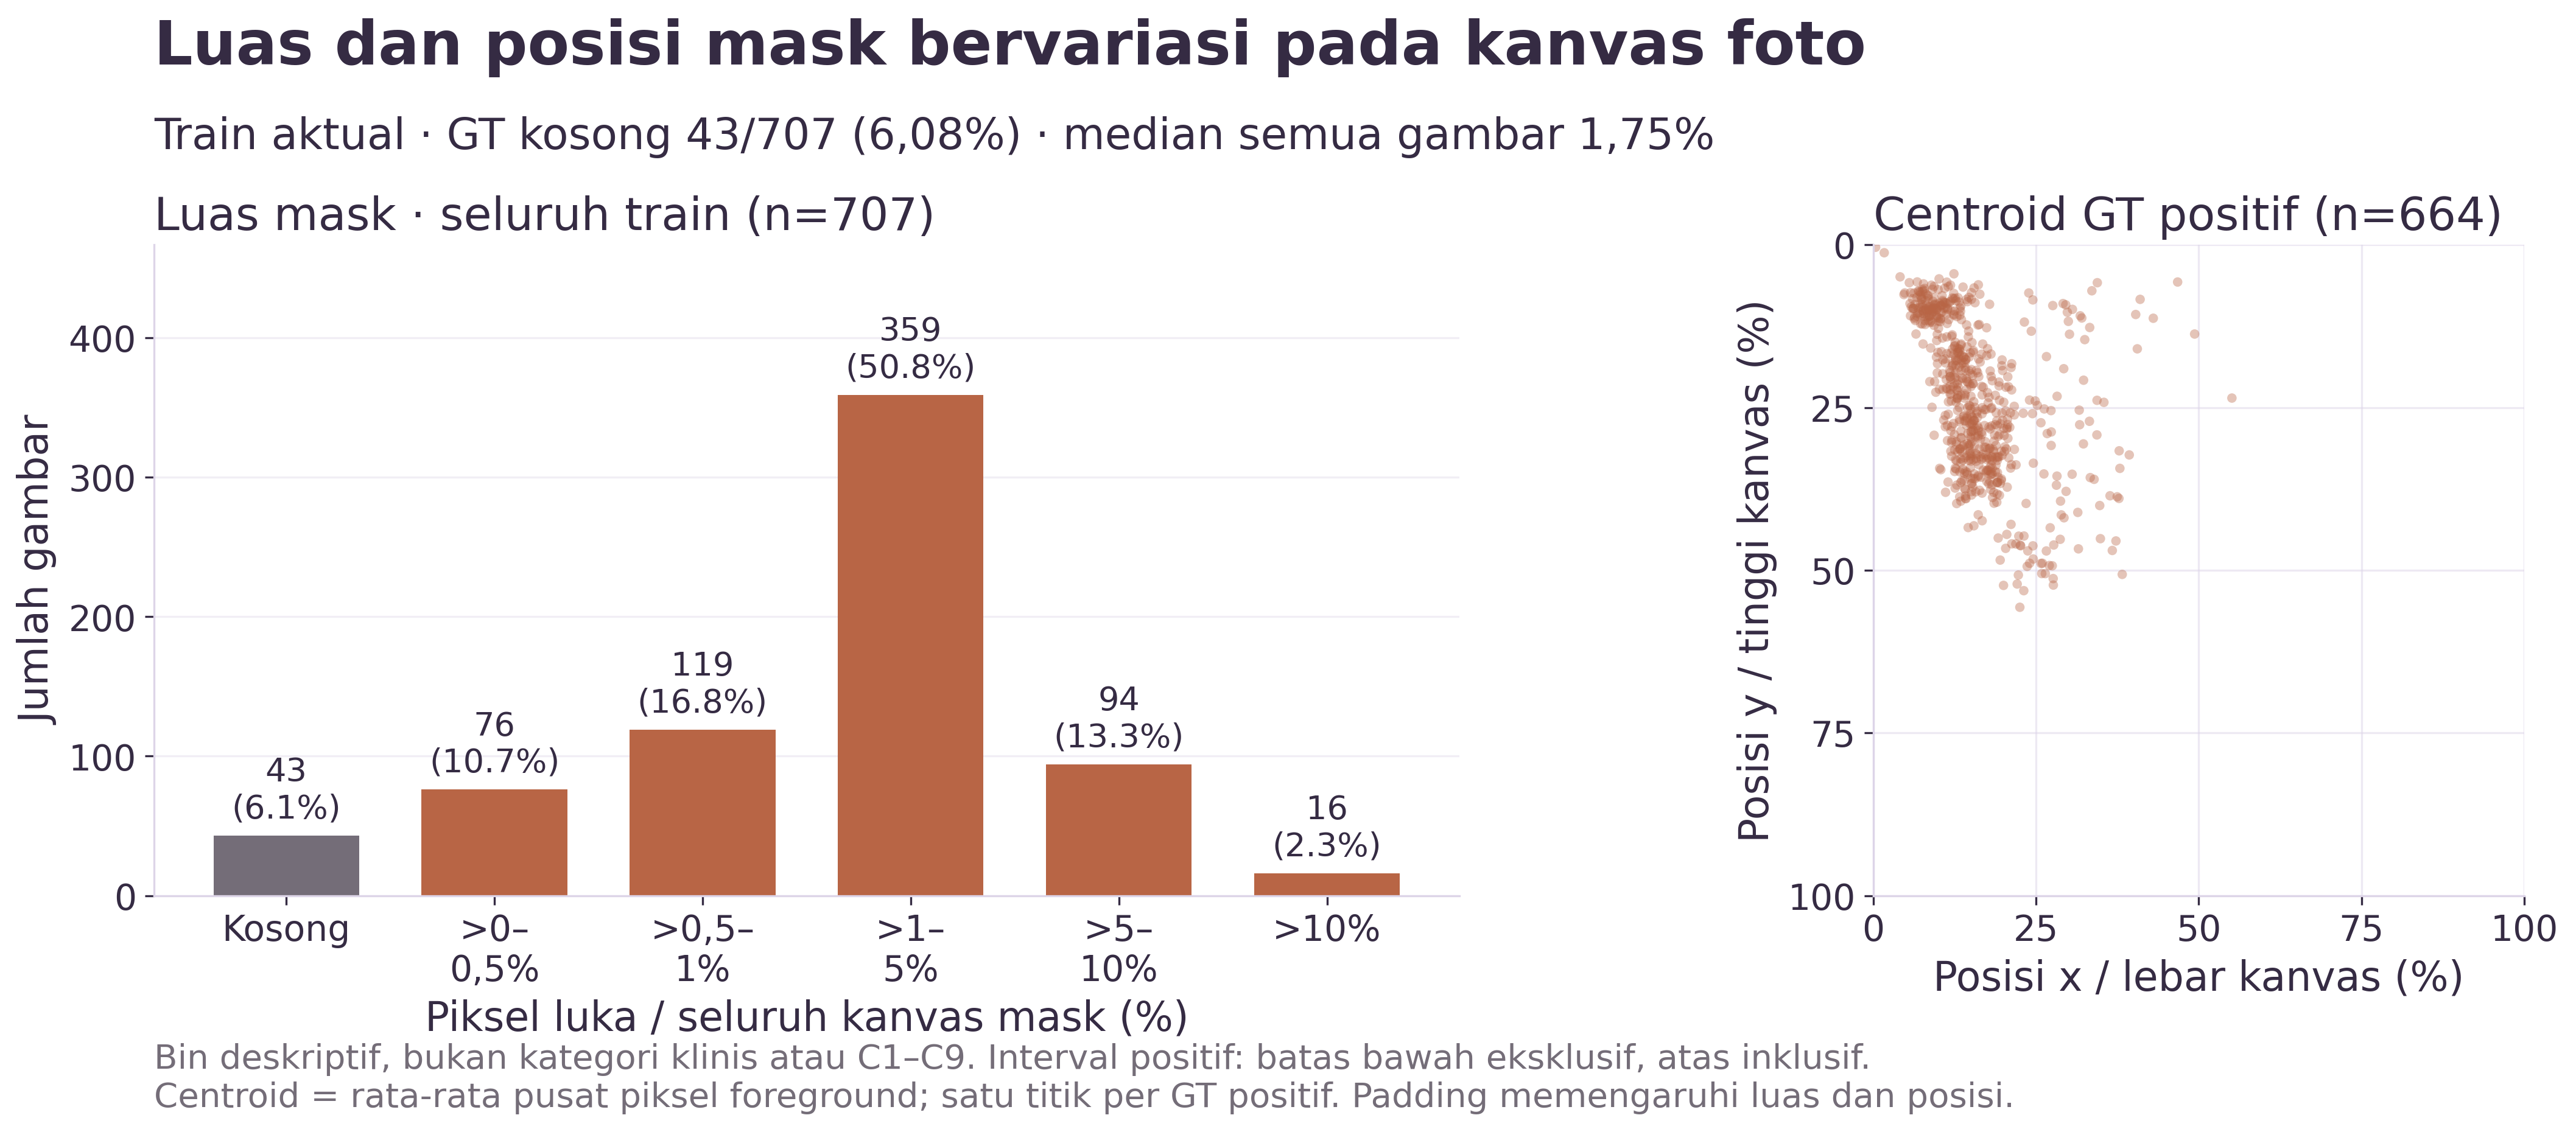

In [4]:
table(stats_table(s))
table(bin_table(s))
print(f"Mean seluruh train = {s['mean_per_image_area_percent_all']:.6f}%; global = {s['foreground_pct_global']:.6f}%")
print('Jumlah bin =',sum(r['count'] for r in s['area_bins']))
figure('02_wound_area_distribution.png')

### 4 · Foto–GT dipilih dengan aturan tetap
Terdekat Q10/Q50/Q90 luas mask positif, ID berbeda, tie menurut filename; ditambah GT kosong pertama
secara leksikografis. Tidak memilih dari validation/test atau berdasarkan hasil model. Galeri adalah contoh
terpilih, bukan sampel acak yang merepresentasikan populasi. Tidak ada diagnosis atau klaim pencahayaan
dari brightness global yang dipengaruhi padding.

sample_id,label,target_area_fraction,luas_aktual_pct,reason
87c73026a0a864fdcddb7e323441fc3b_1.png,Luas rendah · Q10 positif,0.0045,0.4504,Nearest positive-mask area to the linear quantile; distinct IDs; ties by filename
7d2c0b2e71f8641a53815e928581b0fc_0.png,Luas median · Q50 positif,0.0189,1.9013,Nearest positive-mask area to the linear quantile; distinct IDs; ties by filename
a2de360b4a138ad94a17ba6bce918792_0.png,Luas tinggi · Q90 positif,0.0667,6.6845,Nearest positive-mask area to the linear quantile; distinct IDs; ties by filename
0272003ec882522e7bec012aac93cc26_0.png,GT kosong,0.0000,0.0000,Lexicographically first empty GT in actual train


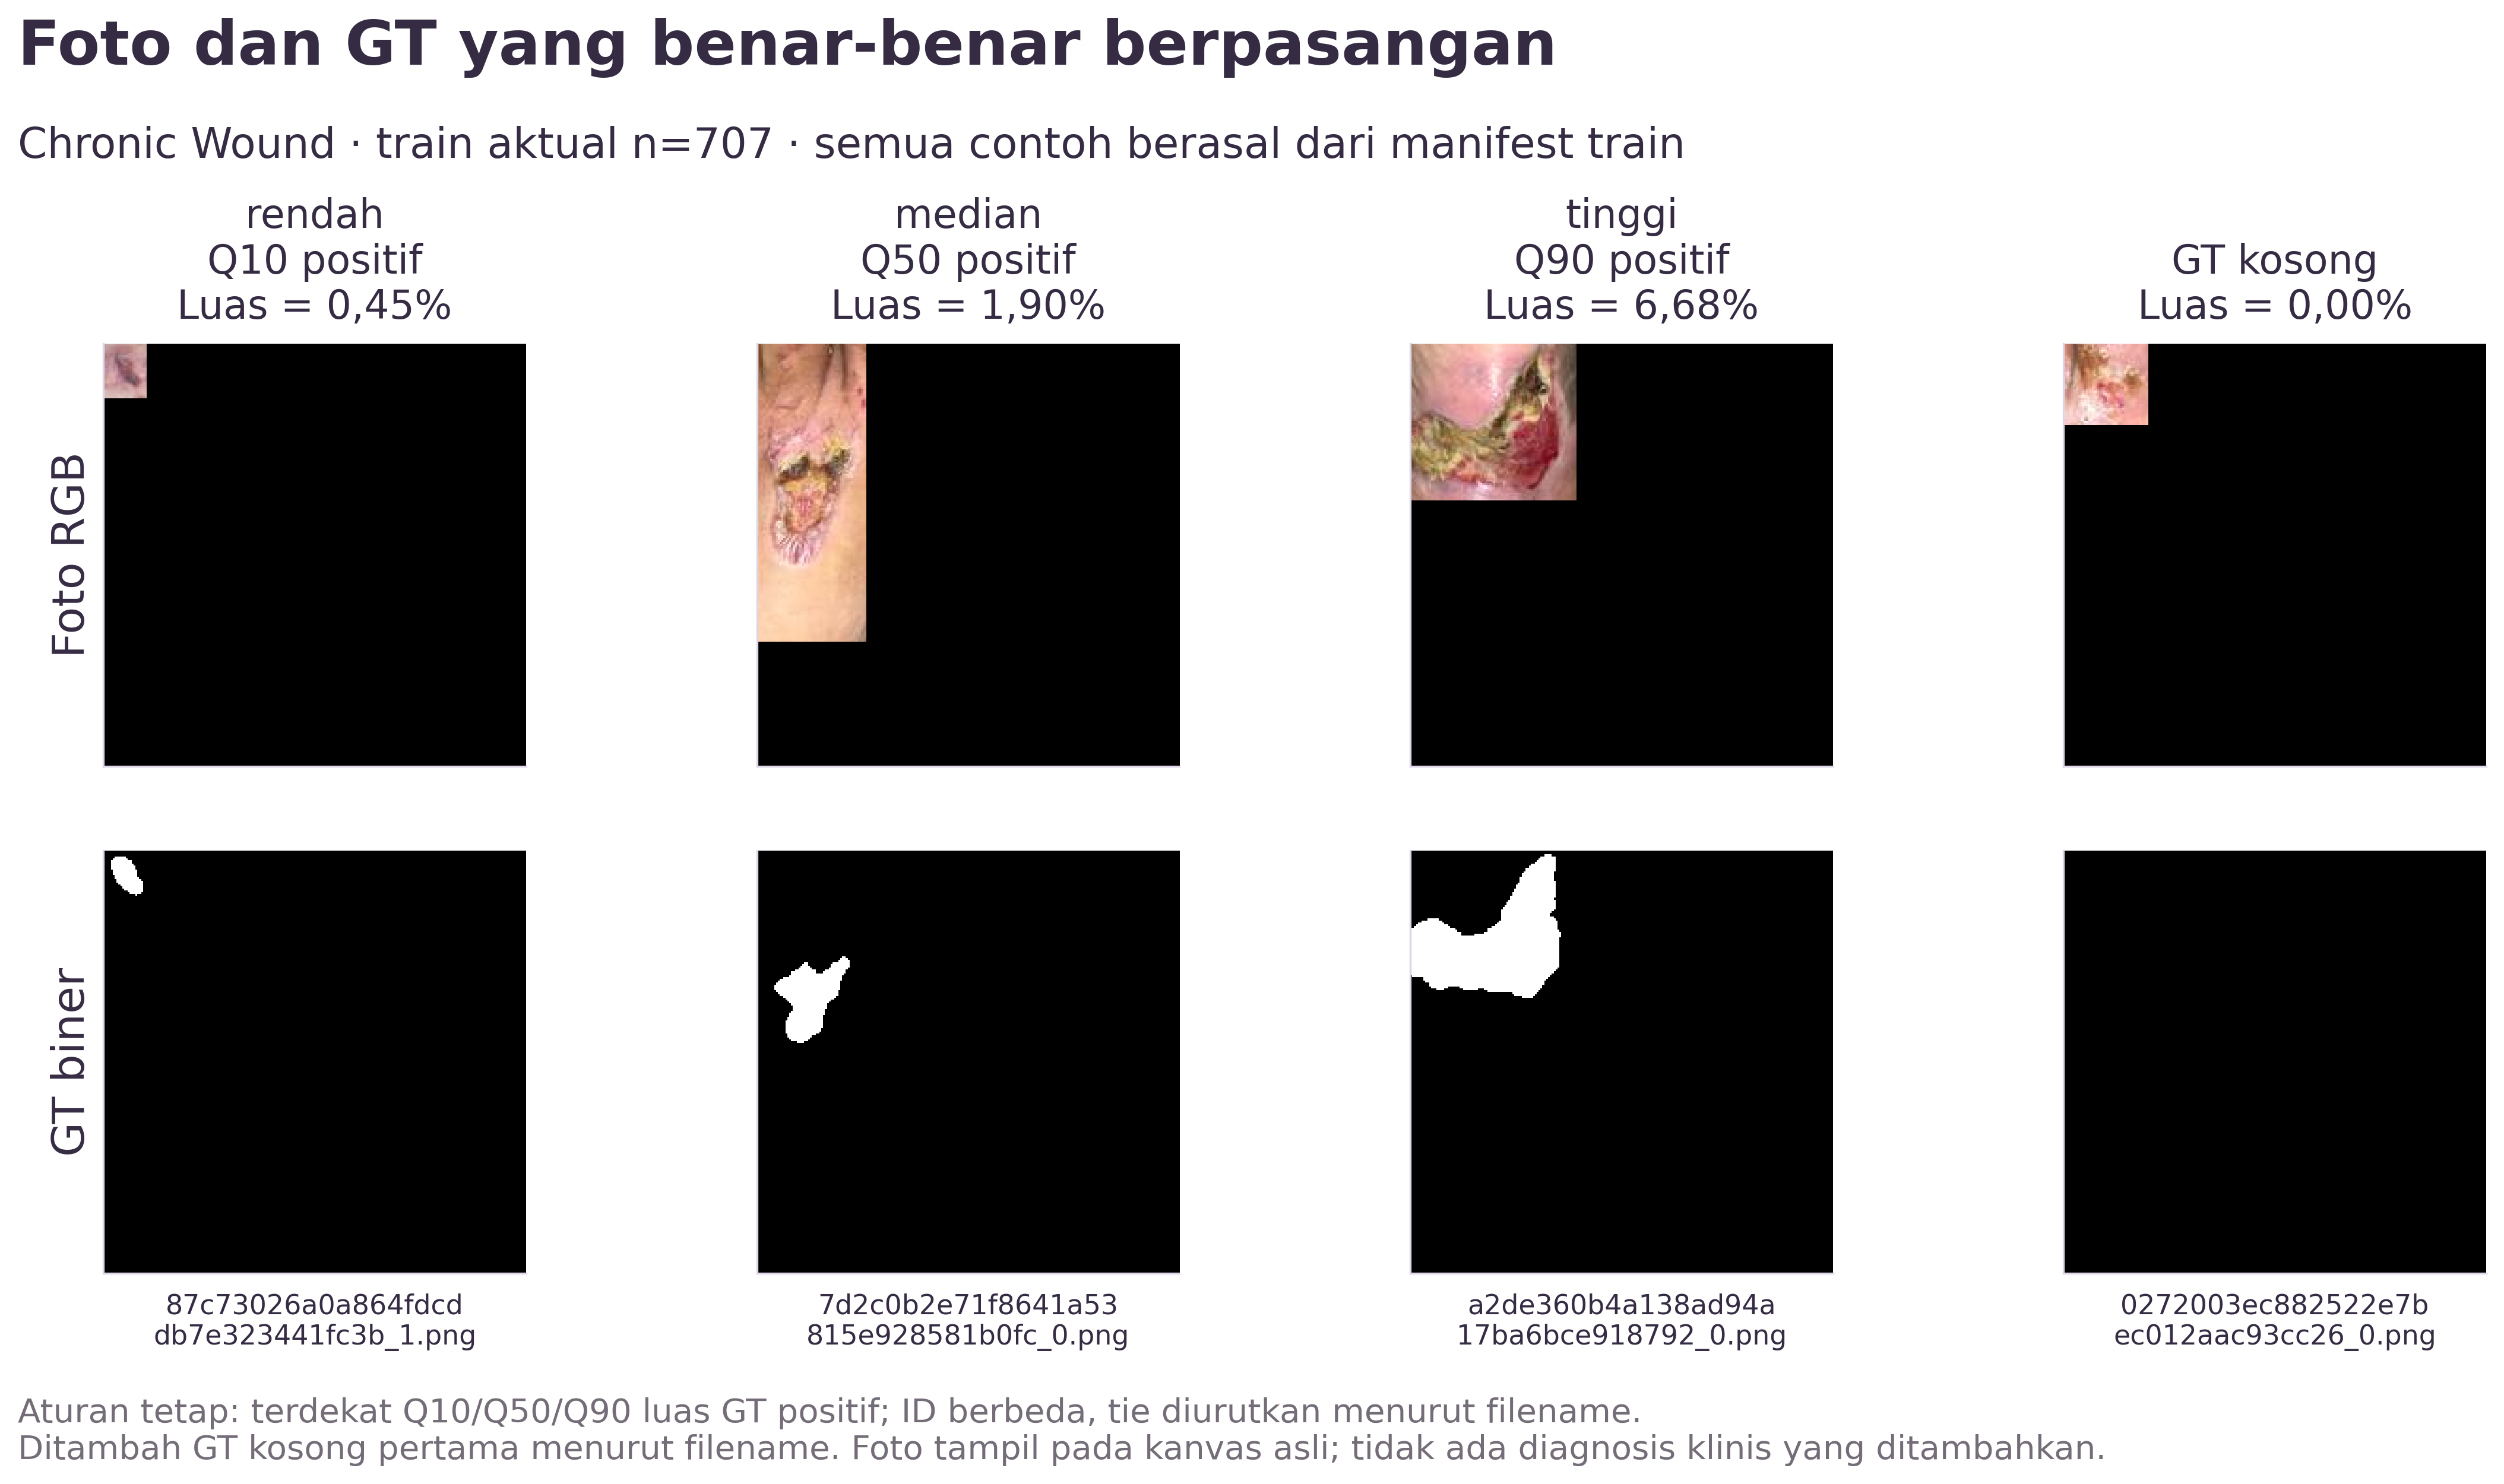

In [5]:
choices=pd.DataFrame(s['example_selection']['examples'])
choices['luas_aktual_pct']=choices.area_fraction*100
table(choices[['sample_id','label','target_area_fraction','luas_aktual_pct','reason']])
figure('03_train_examples.png')

## PENJELASAN METODE DARI PAPER/KODE
**Paper §3.2.3:** Dice + Focal Loss; focal memberi perhatian pada contoh sulit ketika background dominan.
**Table 1 / §3.2.5:** augmentasi geometrik dan intensitas pada training; normalisasi/preprocessing.
**§3.2.2:** arsitektur P-scSE. EDA ini tidak menguji keunggulan arsitektur tersebut.

Alur kode: OpenCV BGR→RGB → mask grayscale÷255 + kanal → augmentasi training berpasangan →
normalisasi ImageNet foto saja → HWC→CHW, float32. Input sudah 224×224; tidak ada resize atau
PadIfNeeded aktif tambahan. Validation/test memakai Compose kosong, dilanjutkan preprocessing yang sama.

Compose training p=0.9; grup OneOf flip p=0.5, affine p=0.9, efek p=0.2, intensitas p=0.2.
`p` anak OneOf adalah bobot pemilihan. Konfigurasi lengkap/default library dan replay disimpan dalam metadata.

In [6]:
display(Markdown(f"**Normalisasi:** mean `{pipeline['normalization']['mean']}`, std `{pipeline['normalization']['std']}`."))
table(pd.DataFrame(pipeline['transform_targets']))
tensor_rows=[]
for kind,items in pipeline['tensors'].items():
    for field in ['image','mask']:
        item=items[field]
        tensor_rows.append({'contoh':kind,'target':field,**{k:item[k] for k in ['shape','dtype','min','max']}})
table(pd.DataFrame(tensor_rows))
table(pd.DataFrame(verification['source_wiring']['engine_calls']))

**Normalisasi:** mean `[0.485, 0.456, 0.406]`, std `[0.229, 0.224, 0.225]`.

class,p,target_kind,targets
HorizontalFlip,0.8000,paired geometry,"[bboxes, image, keypoints, mask, masks]"
VerticalFlip,0.4000,paired geometry,"[bboxes, image, keypoints, mask, masks]"
ShiftScaleRotate,1.0000,paired geometry,"[bboxes, image, keypoints, mask, masks]"
ShiftScaleRotate,1.0000,paired geometry,"[bboxes, image, keypoints, mask, masks]"
ShiftScaleRotate,1.0000,paired geometry,"[bboxes, image, keypoints, mask, masks]"
ShiftScaleRotate,1.0000,paired geometry,"[bboxes, image, keypoints, mask, masks]"
Perspective,1.0000,paired geometry,"[bboxes, image, keypoints, mask, masks]"
GaussNoise,1.0000,image only,[image]
Sharpen,1.0000,image only,[image]
Blur,1.0000,image only,[image]


contoh,target,shape,dtype,min,max
original,image,"[3, 224, 224]",float32,-2.1179,2.6400
original,mask,"[1, 224, 224]",float32,0.0000,1.0000
geometric,image,"[3, 224, 224]",float32,-2.1179,2.4308
geometric,mask,"[1, 224, 224]",float32,0.0000,1.0000
intensity,image,"[3, 224, 224]",float32,-2.1179,2.1346
intensity,mask,"[1, 224, 224]",float32,0.0000,1.0000


function,line,split_expression,augment
make_loaders,45,'train',True
make_loaders,46,'validation',False
evaluate_run,260,split,False


### Demo transformasi: geometri mengubah foto + GT, intensitas mengubah foto saja
Cabang sumber asli diisolasi dan **dipaksa aktif** dalam ReplayCompose(p=1). Probabilitas ini **bukan**
probabilitas training. Foto ditampilkan **sebelum normalisasi ImageNet**; tensor setelah normalisasi
tersimpan terpisah. Tidak ada model dibangun atau weights dimuat. Definisi diekstrak melalui AST loader aman.
Cabang rotate baseline mempunyai shift_limit=0; x-FUSegNet mempunyai 0.1. Demo utama mengikuti baseline.

demo,seed,konfigurasi,parameter_aktual
geometric,20261030,"{'__class_fullname__': 'ShiftScaleRotate', 'always_apply': False, 'p': 1, 'shift_limit_x': [0, 0], 'shift_limit_y': [0, 0], 'scale_limit': [0.0, 0.0], 'rotate_limit': [-30, 30], 'interpolation': 1, 'border_mode': 0, 'value': None, 'mask_value': None, 'rotate_method': 'largest_box'}","{'angle': 21.930167114061994, 'scale': 1.0, 'dx': 0.0, 'dy': 0.0}"
intensity,20261032,"{'__class_fullname__': 'RandomBrightnessContrast', 'always_apply': False, 'p': 1, 'brightness_limit': [-0.2, 0.2], 'contrast_limit': [-0.2, 0.2], 'brightness_by_max': True}","{'alpha': 1.0265223972354294, 'beta': -0.13999388674283325}"


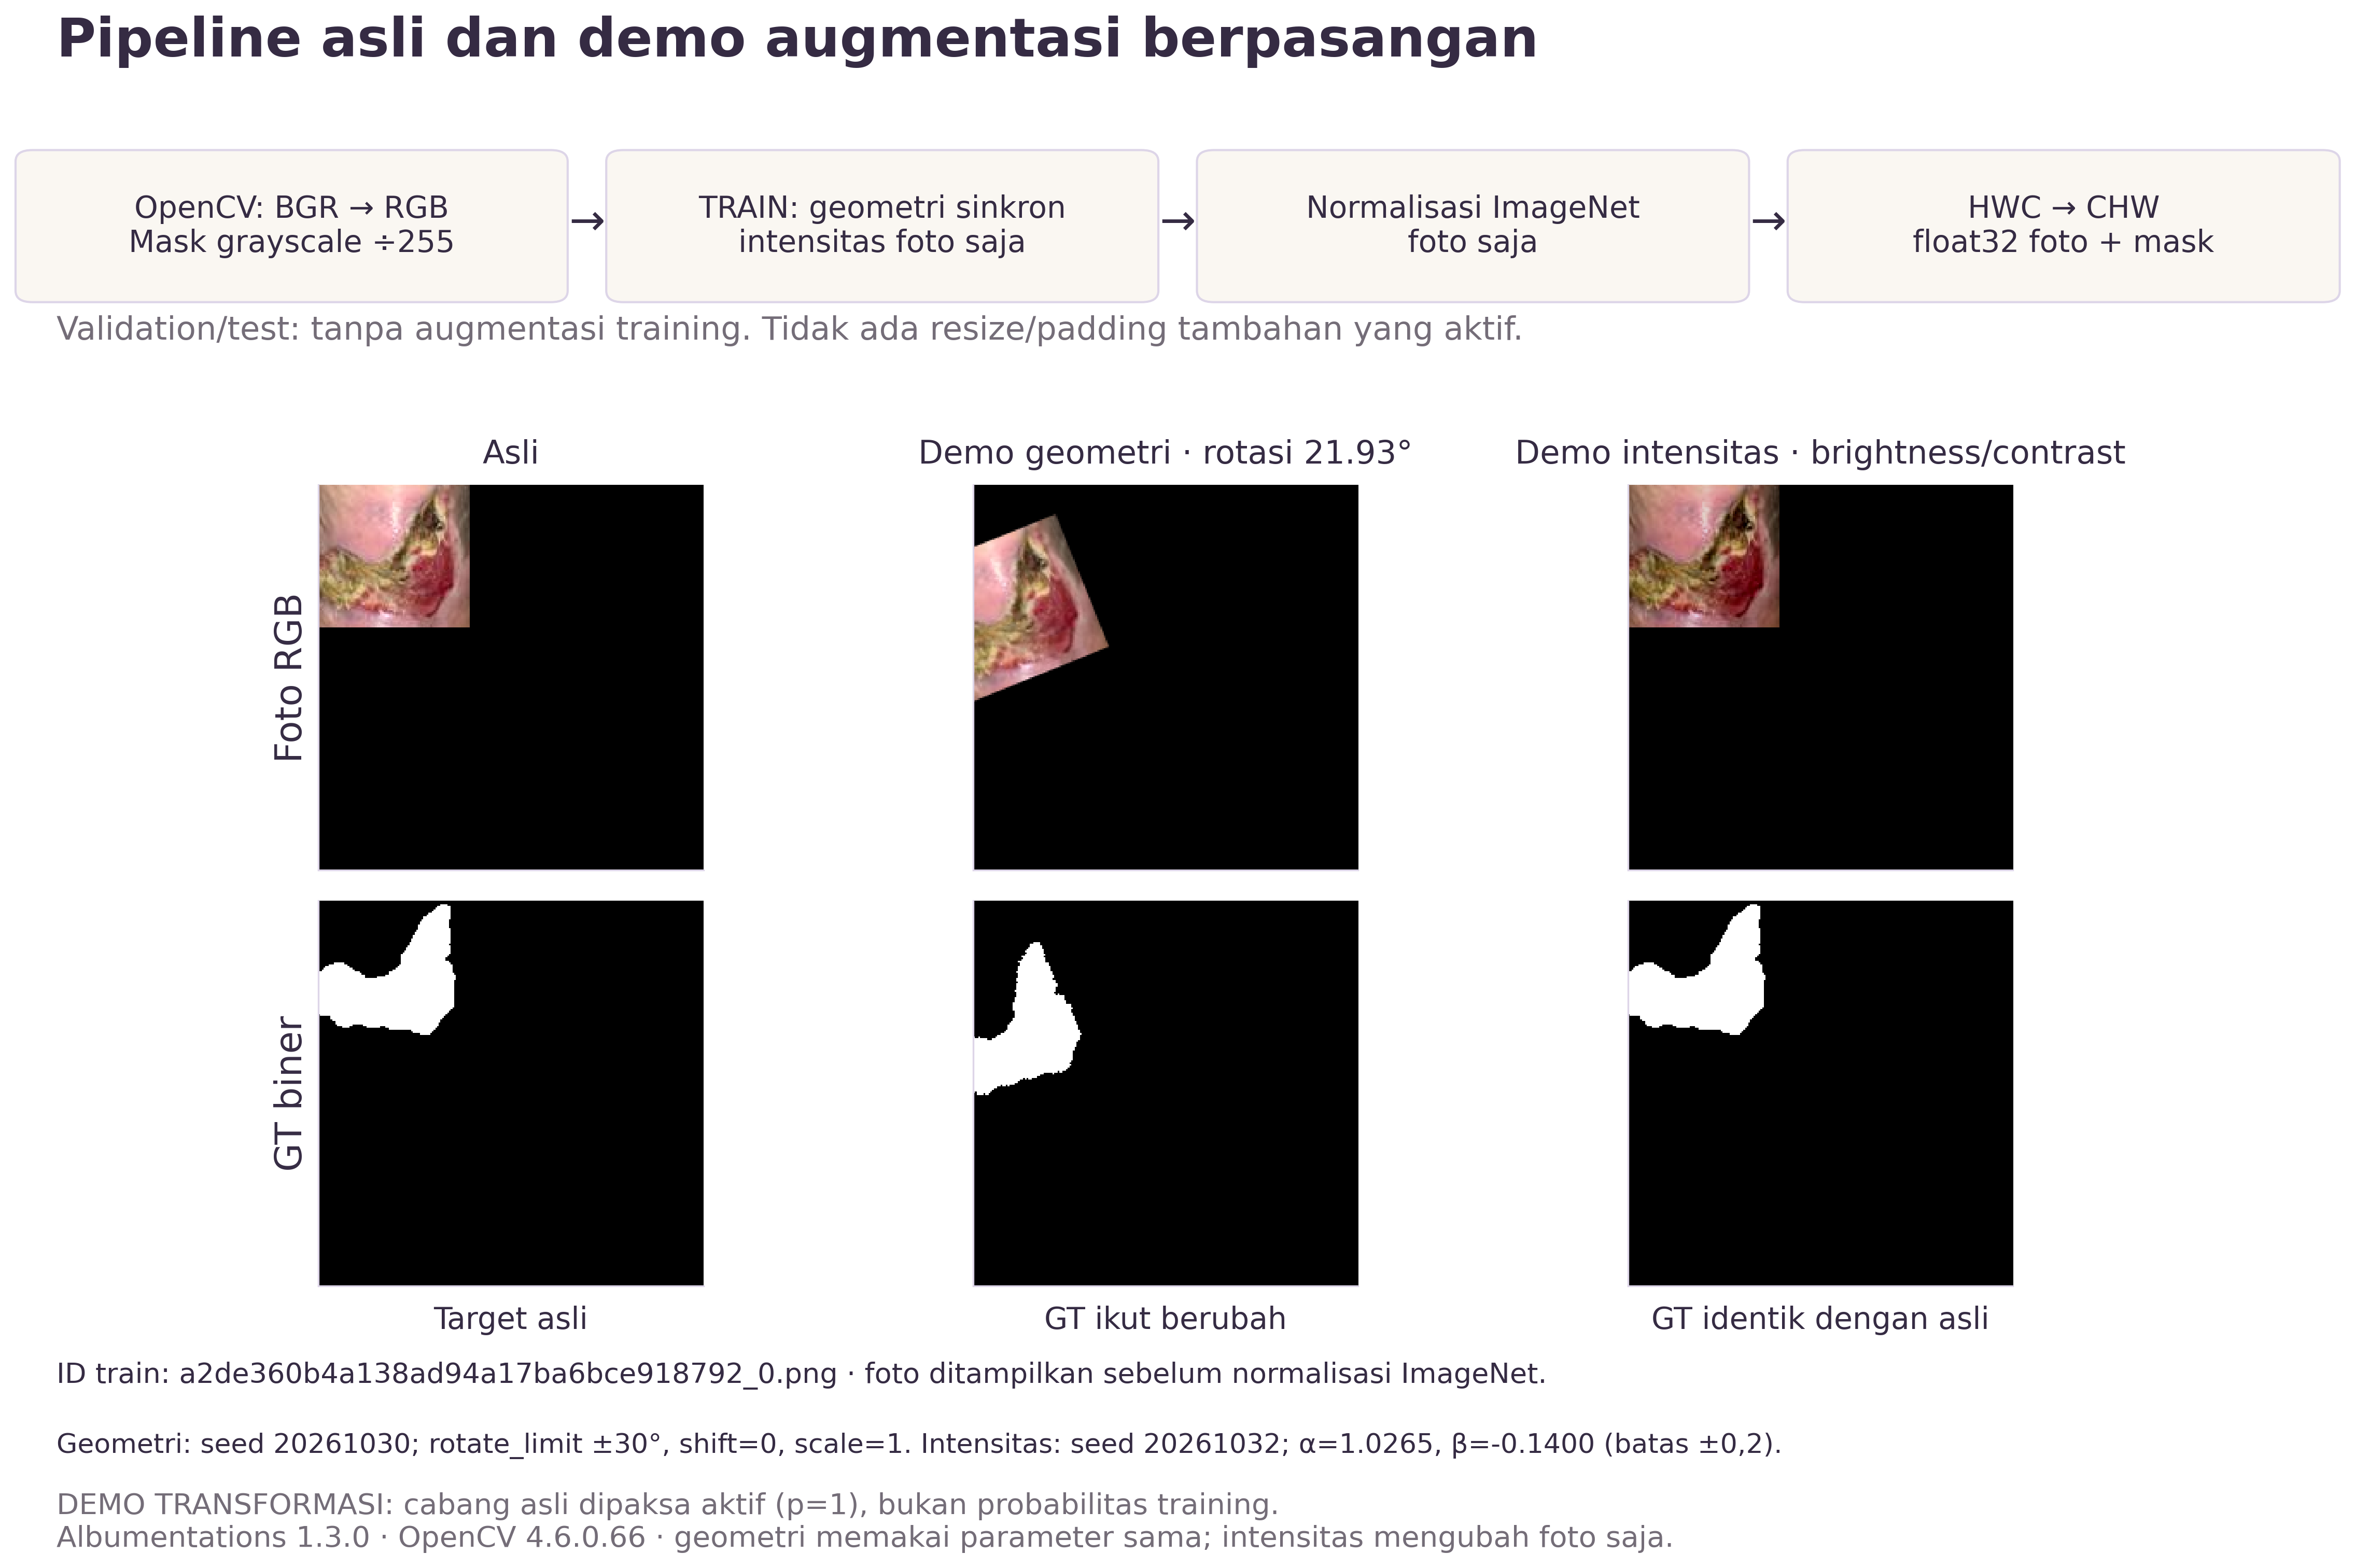

In [7]:
rows=[]
for kind in ['geometric','intensity']:
    demo=pipeline[kind]
    rows.append({'demo':kind,'seed':demo['seed'],'konfigurasi':str(demo['transform']['transform']),
                 'parameter_aktual':str(demo['replay']['transforms'][0]['params'])})
table(pd.DataFrame(rows))
figure('04_preprocessing_augmentation.png')

## INTERPRETASI ATAU HIPOTESIS KAMI
Dominasi background memberi konteks alasan Focal Loss; variasi luas/posisi dan tampilan contoh foto
memberi konteks augmentasi penulis. **EDA tidak membuktikan Focal Loss, augmentasi, atau P-scSE lebih baik**;
klaim itu membutuhkan eksperimen terkontrol. Mask biner menjelaskan target yang dipelajari model.

**Batas:** seluruh kanvas termasuk padding; tidak ada ukuran fisik/diagnosis; duplikat dipertahankan;
identitas pasien/luka yang memadai tidak tersedia sehingga independensi pasien belum terverifikasi.
Audit terdahulu menemukan 2 validation dan 16 test dengan RGB identik di actual train
([laporan sebelumnya](../reports/cp1-analysis-01.md)); itu bukan statistik EDA train baru.
Membership asli train/validation penulis tidak tersedia; ini manifest baseline lokal yang pasti dipakai.

In [8]:
groups=s['within_train_rgb_duplicate_groups']
print(f"Di dalam actual train: {len(groups)} grup RGB identik, melibatkan {sum(map(len,groups))} gambar. Tidak dihapus.")
table(pd.DataFrame([{'grup':i+1,'sample_ids':', '.join(ids)} for i,ids in enumerate(groups)]))
display(Markdown('**Versi environment yang dipakai:**'))
table(pd.DataFrame([{'fungsi':group,'dependency':k,'versi':v} for group,items in s['dependencies'].items()
                    for k,v in items.items()]))
print('Pemeriksaan inti:',verification)
print('CSV SHA-256:',sha(CSV))

Di dalam actual train: 11 grup RGB identik, melibatkan 22 gambar. Tidak dihapus.


grup,sample_ids
1,"4cb7afba9a7708f2dd1fe874de7cc56d_0.png, 440078c6936219a7a496ebc67228d5d5_0.png"
2,"440078c6936219a7a496ebc67228d5d5_1.png, 4cb7afba9a7708f2dd1fe874de7cc56d_1.png"
3,"1576e366442683aac204404e081eb938_2.png, 22476241644edd0ccb41dc9d27c26d3b_2.png"
4,"816b2c8cbdaa48026c25f79587082816_0.png, 870640cd12cfdfe8366e97db14227891_0.png"
5,"1576e366442683aac204404e081eb938_1.png, 22476241644edd0ccb41dc9d27c26d3b_1.png"
6,"6fed027b91cec55f75de19f29b9a972f_0.png, b9fff21bebb15ba7d8c3f54063e37799_0.png"
7,"1c27d8289cbfa6a1a0da01d7ec757a46_0.png, 3ed2bf6e2ef1d94d42c949a841a561d3_0.png"
8,"97afdc101911ffc33d0fc166cacbaf1b_0.png, 52ef1e670e4b103c7fd06e24ba0a07ec_0.png"
9,"22476241644edd0ccb41dc9d27c26d3b_3.png, 1576e366442683aac204404e081eb938_3.png"
10,"484aa6be0ea024aadc8f154b7c637a6f_0.png, 5f1aa951a7c2daf54acd85dcd6fe5c06_0.png"


**Versi environment yang dipakai:**

fungsi,dependency,versi
data_and_augmentation,python,3.10.4
data_and_augmentation,interpreter,/home/nafisnaufal1426/fuseg/orie/.venv-training/bin/python
data_and_augmentation,numpy,1.22.4
data_and_augmentation,pandas,1.4.2
data_and_augmentation,Pillow,9.1.1
data_and_augmentation,opencv-python-headless,4.6.0.66
data_and_augmentation,albumentations,1.3.0
data_and_augmentation,torch,1.11.0+cu113
data_and_augmentation,torchvision,0.12.0+cu113
plot_and_notebook,python,3.10.4


Pemeriksaan inti: {'membership_matches_saved_run': True, 'n_actual_train_verified': 707, 'pairs_unique_and_matching': True, 'raw_image_mask_sha256_verified': True, 'raw_pixel_counts_recomputed': True, 'binary_values_checked_before_binarization': True, 'pixel_accounting_valid': True, 'area_fractions_in_range': True, 'bins_cover_train_once': True, 'all_and_positive_statistics_recomputed': True, 'gallery_train_membership_verified': True, 'demo_tensors_and_pairing_verified': True, 'no_validation_test_pixel_statistics': True, 'source_wiring': {'make_dataset_default_augment': False, 'engine_calls': [{'function': 'make_loaders', 'line': 45, 'split_expression': "'train'", 'augment': True}, {'function': 'make_loaders', 'line': 46, 'split_expression': "'validation'", 'augment': False}, {'function': 'evaluate_run', 'line': 260, 'split_expression': 'split', 'augment': False}], 'validation_and_evaluation_skip_training_augmentation': True, 'verification': 'AST of frozen project data.py and engine.py

## Dua slide yang disarankan
**Satu slide EDA (~50 detik):** komposisi piksel + panel bin luas. Sebut luka/background,
rasio BG:FG, GT kosong; footer “707 train aktual, seluruh kanvas termasuk padding”.
Tutup dengan “konteks metode penulis, belum bukti manfaat”. Centroid/galeri sebagai cadangan.

**Satu slide preprocessing (~50 detik):** diagram alur + galeri asli/geometri/intensitas,
dengan GT yang berubah/tetap. Sebut demo dipaksa aktif, val/test tanpa augmentasi training,
tidak ada resize tambahan, dan normalisasi ImageNet untuk foto saja.

Sumber: [paper](https://arxiv.org/abs/2305.02961v2), [laporan lengkap](../reports/cp1-eda-01.md),
[CSV](../reports/tables/cp1-eda-per-image.csv), [JSON](../reports/tables/cp1-eda-summary.json),
[manifest aktual](../reports/tables/cp1-eda-split-manifest.json),
[metadata/replay](../reports/tables/cp1-eda-preprocessing.json), dan
[figure PNG/SVG](../reports/figures/cp1-eda-01/).
Foto/GT terpilih berasal dari [Chronic Wound publik UWM](https://github.com/uwm-bigdata/wound-segmentation/tree/master/data/wound_dataset).
Raw dataset, checkpoint, dan tensor preprocessing tetap lokal. Untuk mengeksekusi ulang verifikasi,
diperlukan raw data, snapshot source, dan artefak run baseline lokal; tidak perlu training/inference.